As a Data analyst at the Anderson Cancer Center, I have been tasked with developing a model to address the growing number of referrals at the center. This model's first step is to identify essential variables for securing donor funding. After consulting with my team, Principal Component Analysis (PCA) has been chosen as the most suitable technique for this task.

In [ ]:
# Load: what are the rows, the columns, and the labels?
# Clean: any missing values, duplicates, or impossible values? Do the feature scales differ?
# Scale: are the features in different units? If so, standardize X (never y).
# PCA: how much variance do the components keep, and how many do I need?
# Plot: do the classes separate, even though PCA never saw them?
# Validate: does a classifier on the reduced data still identify the classes on unseen tumours?

Load and inspect the data

In [35]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


data = load_breast_cancer()
x = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

In [27]:
print(x.shape)
print(x.head())
print(x.describe().T[["mean", "std", "min", "max"]].sort_values(by='std', ascending=False))
print(pd.Series(y).value_counts())

(569, 30)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0 

In [28]:
# 1. Missing values
print(x.isnull().sum().sum())

# 2. Data types
print(x.dtypes.value_counts())

# 3. Duplicate rows
print(x.duplicated().sum())

# 4. Obvious impossible values (e.g. negative areas or radii)
print((x < 0).sum().sum())

0
float64    30
Name: count, dtype: int64
0
0


Scale the features

In [29]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)

X_scaled_df = pd.DataFrame(X_scaled, columns=x.columns)
print(X_scaled_df.mean().round(3).head())
print(X_scaled_df.std().round(3).head())

mean radius       -0.0
mean texture       0.0
mean perimeter    -0.0
mean area         -0.0
mean smoothness   -0.0
dtype: float64
mean radius        1.001
mean texture       1.001
mean perimeter     1.001
mean area          1.001
mean smoothness    1.001
dtype: float64


In [ ]:
Fit PCA and look at explained variance

Fit PCA and look at explained variance

In [31]:
pca = PCA()                      # no n_components given, so keep all 30
pca.fit(X_scaled)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

print(explained[:5].round(3))
print(cumulative[:13].round(3))

[0.443 0.19  0.094 0.066 0.055]
[0.443 0.632 0.726 0.792 0.847 0.888 0.91  0.926 0.94  0.952 0.961 0.97
 0.978]


In [32]:
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

print(X_pca2.shape)                       # (569, 2)
print(pca2.explained_variance_ratio_)

(569, 2)
[0.44272026 0.18971182]


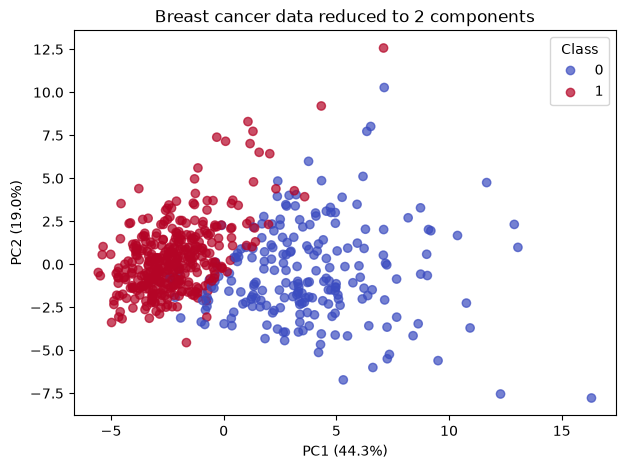

In [34]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=y, cmap="coolwarm", alpha=0.7)
plt.xlabel("PC1 (44.3%)")
plt.ylabel("PC2 (19.0%)")
plt.title("Breast cancer data reduced to 2 components")
plt.legend(*scatter.legend_elements(), title="Class")
plt.show()

# What the plot shows
# Red (class 1, benign) forms a dense cluster on the left, centered near PC1 ≈ -2 to 0.
# Blue (class 0, malignant) is more spread out and sits mostly to the right.
# They overlap in the middle. That's expected with only 2 components, which keep 63.2% of the variance (your 44.3% + 19.0%). The other 36.8% is gone, and some of what separates the classes was in it.

Validate the 2 components with logistic regression

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pca2, y, test_size=0.2, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

0.945054945054945
0.9912280701754386


In [37]:
for seed in [0, 1, 2, 3, 4]:
    X_train, X_test, y_train, y_test = train_test_split(
        X_pca2, y, test_size=0.2, random_state=seed
    )
    m = LogisticRegression().fit(X_train, y_train)
    print(seed, round(m.score(X_test, y_test), 3))

0 0.93
1 0.947
2 0.93
3 0.93
4 0.921
